# WEEK 4 — Z-Transform Laboratory: Poles, Zeros and Stability

**Unit:** Unit 2 — Z-Transform, ROC, Inverse Z-Transform and Stability

**Name:** Tedy Deodatus Mlengera

**Registration Number:** 230242409456

**Date:** 26 November 2026

**Group:** 08


## Pre-lab Preparation

### Question (a): Find the Poles and Determine Stability

Given:

\[
H(z)=\frac{1}{1-0.9z^{-1}+0.81z^{-2}}
\]

Multiplying the denominator by \(z^2\):

\[
z^2-0.9z+0.81=0
\]

Using the quadratic formula:

\[
z=\frac{0.9\pm\sqrt{0.9^2-4(0.81)}}{2}
\]

\[
z=0.45\pm j0.7794
\]

The magnitude of each pole is:

\[
|p|=\sqrt{0.45^2+0.7794^2}=0.9
\]

Since both poles have magnitude less than 1, the causal system is stable.

### Question (b): Partial-Fraction Expansion

Given:

\[
X(z)=\frac{1}{(1-0.5z^{-1})(1-0.25z^{-1})}
\]

Using partial fractions:

\[
X(z)=\frac{A}{1-0.5z^{-1}}+
\frac{B}{1-0.25z^{-1}}
\]

Solving for A and B:

\[
A=2,\qquad B=-1
\]

Therefore:

\[
\boxed{
X(z)=\frac{2}{1-0.5z^{-1}}
-\frac{1}{1-0.25z^{-1}}
}
\]


## TASK 4.1 — A POLE-ZERO PLOTTING FUNCTION

**Objective:** To plot the poles and zeros of a transfer function and examine its frequency response.

A zero is a root of the numerator of a transfer function, while a pole is a root of its denominator.

The pole-zero plot helps us understand the behaviour and stability of a digital system.


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio, display

print("All libraries imported successfully.")


All libraries imported successfully.


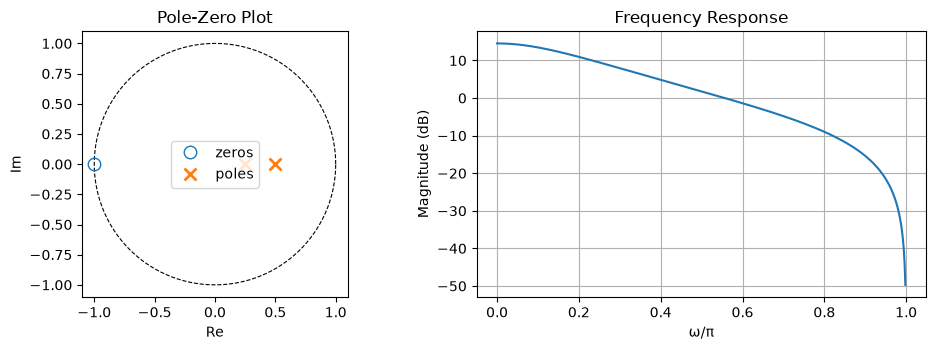

Zeros: [-1.]
Poles: [0.5  0.25]
Stable: True


In [2]:

# Task 4.1: Pole-zero plotting function

def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)

    if ax is None:
        ax = plt.gca()

    th = np.linspace(0, 2*np.pi, 400)

    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)
    ax.plot(z.real, z.imag, "o", mfc="none",
            ms=9, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=9,
            mew=2, label="poles")

    ax.set_aspect("equal")
    ax.legend()
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")
    ax.set_title("Pole-Zero Plot")

    return z, p


# Transfer function coefficients
b = [1, 1]
a = [1, -0.75, 0.125]

# Create two plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))

# Plot poles and zeros
z, p = zplane(b, a, ax1)

# Calculate frequency response
w, H = signal.freqz(b, a, worN=512)

# Plot frequency response
ax2.plot(w/np.pi, 20*np.log10(np.abs(H)))
ax2.set_xlabel("ω/π")
ax2.set_ylabel("Magnitude (dB)")
ax2.set_title("Frequency Response")
ax2.grid()

plt.tight_layout()
plt.show()

# Display poles, zeros and stability
print("Zeros:", z)
print("Poles:", p)
print("Stable:", np.all(np.abs(p) < 1))



### Results and Observations

1. The system has one zero located at z = -1.
2. The system has two poles located at z = 0.5 and z = 0.25.
3. Both poles are inside the unit circle.
4. The frequency response shows how the system responds to different frequencies.
5. Since all poles have magnitudes less than 1, the system is stable.

**Conclusion:**

The pole-zero plot and frequency response were successfully obtained using SciPy. The system is stable because all its poles lie inside the unit circle.



## TASK 4.2 — INVERSE Z-TRANSFORM WITH RESIDUEZ

**Objective:** To calculate the inverse z-transform using partial-fraction expansion and verify the impulse response using SciPy's lfilter function.

The residuez function calculates the residues, poles and direct terms of a rational transfer function.

The lfilter function is used to calculate the output of a digital filter.


In [3]:

# Task 4.2: Inverse z-transform using residuez

# Define transfer function
b = [1]
a = [1, -0.75, 0.125]

# Calculate residues, poles and direct terms
r, p, k = signal.residuez(b, a)

print("Residues:", r)
print("Poles:", p)
print("Direct terms:", k)

# Generate 10 samples
n = np.arange(10)

# Calculate inverse z-transform using partial fractions
x_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real

# Calculate impulse response using lfilter
impulse = np.zeros(10)
impulse[0] = 1

x_lf = signal.lfilter(b, a, impulse)

# Display both results
print("\nInverse z-transform:")
print(x_pf)

print("\nImpulse response using lfilter:")
print(x_lf)

# Compare the results
print("\nAre the results equal?")
print(np.allclose(x_pf, x_lf))


Residues: [-1.  2.]
Poles: [0.25 0.5 ]
Direct terms: []

Inverse z-transform:
[1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]

Impulse response using lfilter:
[1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]

Are the results equal?
True


In [4]:

# Task 4.2: Verify the impulse response for b = [1, 1]

b = [1, 1]
a = [1, -0.75, 0.125]

# Calculate residues and poles
r, p, k = signal.residuez(b, a)

print("Residues:", r)
print("Poles:", p)

# Generate 10 samples
n = np.arange(10)

# Calculate inverse z-transform
x_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real

# Calculate impulse response using lfilter
impulse = np.zeros(10)
impulse[0] = 1

x_lf = signal.lfilter(b, a, impulse)

# Required theoretical impulse response
h_theory = 6*(0.5)**n - 5*(0.25)**n

# Display results
print("\nInverse z-transform:")
print(x_pf)

print("\nImpulse response using lfilter:")
print(x_lf)

print("\nTheoretical impulse response:")
print(h_theory)

# Verify results
print("\nInverse z-transform matches lfilter:",
      np.allclose(x_pf, x_lf))

print("Matches theoretical equation:",
      np.allclose(x_lf, h_theory))


Residues: [-5.  6.]
Poles: [0.25 0.5 ]

Inverse z-transform:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Impulse response using lfilter:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Theoretical impulse response:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Inverse z-transform matches lfilter: True
Matches theoretical equation: True



### Comparison of Residues with Pre-lab Answer

The residues obtained using the residuez function were 2 and -1, with poles at 0.5 and 0.25 respectively.

These results agree with the partial-fraction expansion obtained in Pre-lab Question (b).

For the Task 4.1 system, using b = [1, 1] and a = [1, -0.75, 0.125], the residues were 6 and -5.

The inverse z-transform was confirmed as:

h(n) = 6(0.5)^n - 5(0.25)^n

The results were also verified using the lfilter function.

**Conclusion:** The Python results agree with the theoretical calculations.



## TASK 4.3 — POLE POSITION AND THE IMPULSE RESPONSE

**Objective:** To investigate how the pole radius affects the impulse response, oscillation, frequency response and stability of a digital system.

The pole pair is:

p = r e^(±jπ/4)

The experiment uses five different values of r: 0.5, 0.8, 0.95, 1.0 and 1.05.


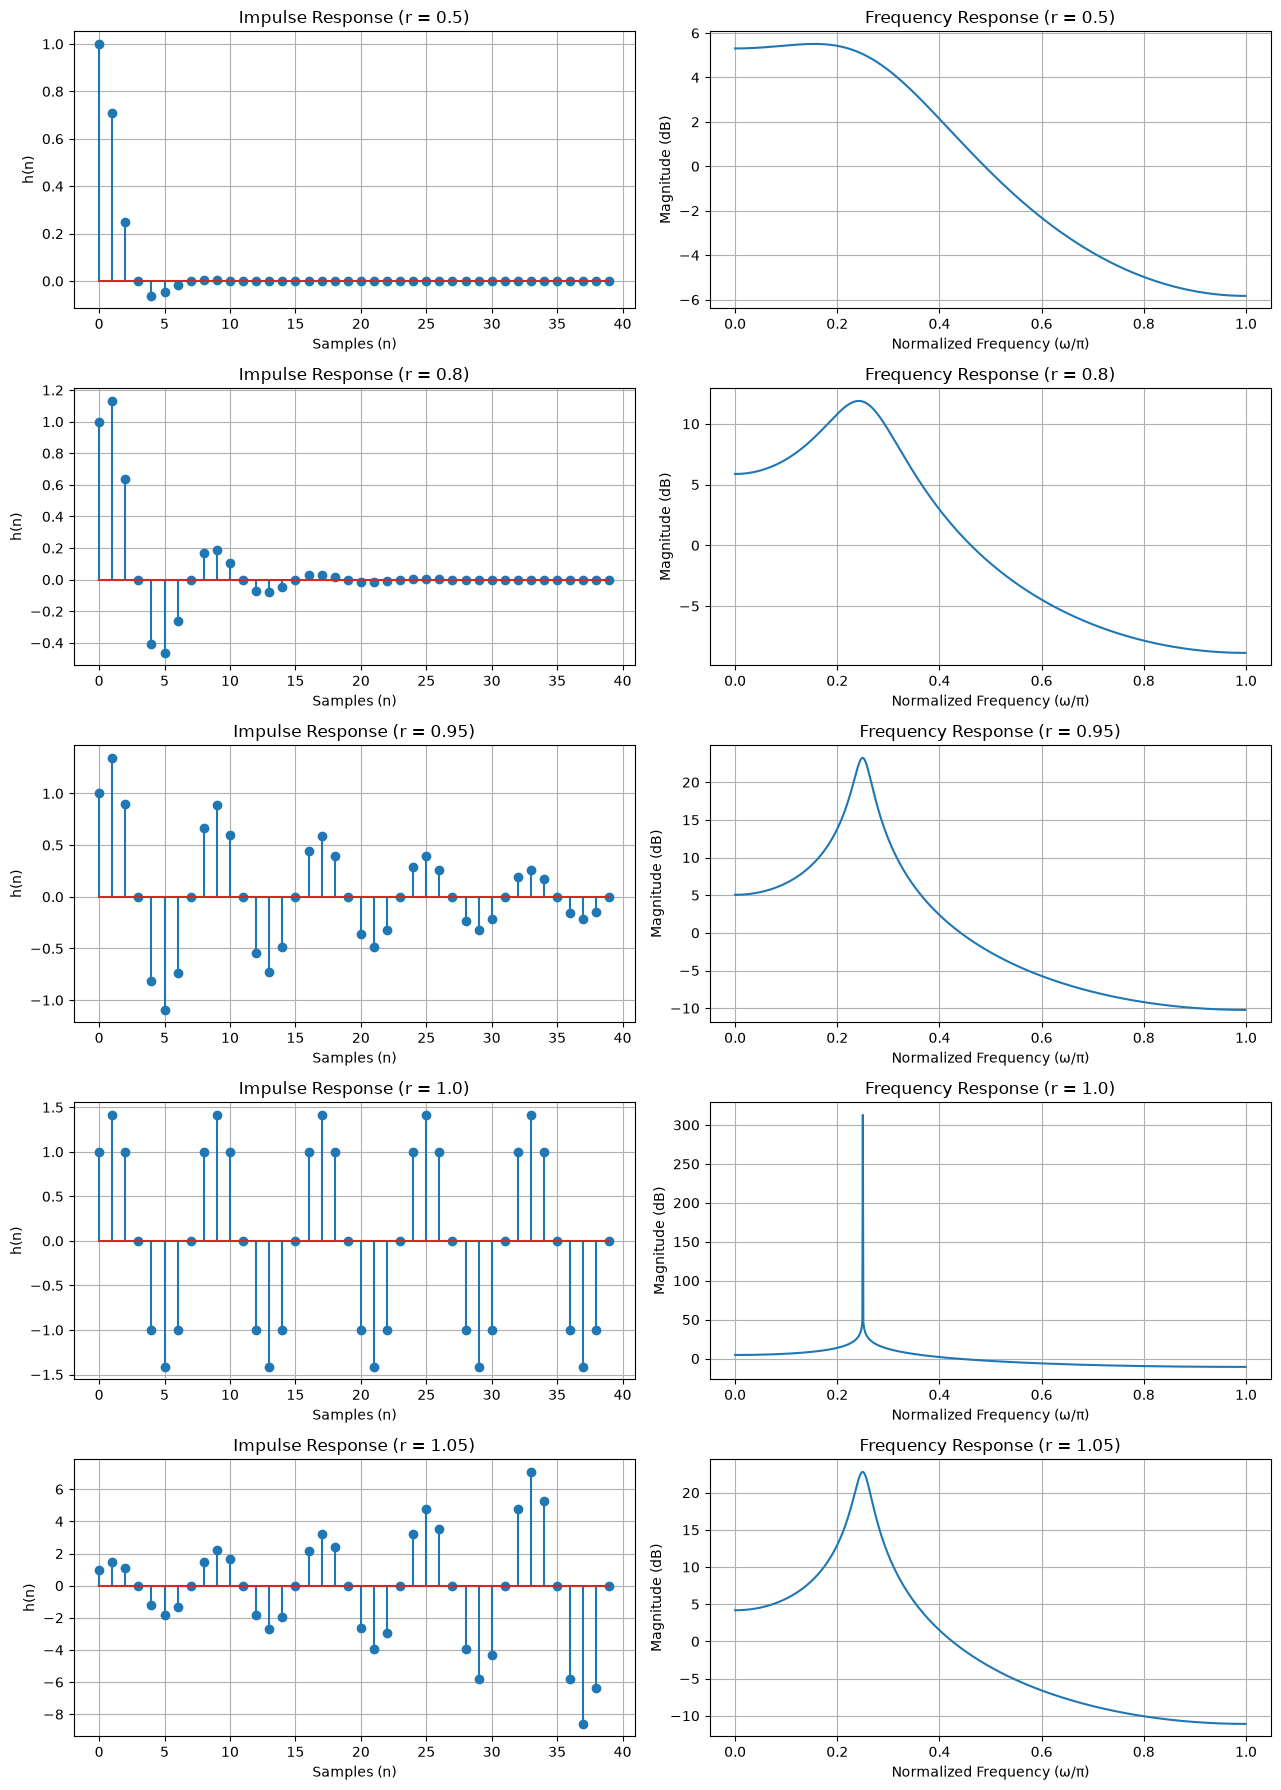

In [5]:

# TASK 4.3: Pole Position and Impulse Response

r_values = [0.5, 0.8, 0.95, 1.0, 1.05]
theta = np.pi / 4

n = np.arange(40)

fig, axes = plt.subplots(5, 2, figsize=(13, 18))

for i, r in enumerate(r_values):

    # Denominator coefficients
    a = [1, -2*r*np.cos(theta), r**2]

    # Numerator coefficients
    b = [1]

    # Generate impulse signal
    impulse = np.zeros(40)
    impulse[0] = 1

    # Calculate impulse response
    h = signal.lfilter(b, a, impulse)

    # Calculate frequency response
    w, H = signal.freqz(b, a, worN=1024)

    # Impulse response plot
    axes[i, 0].stem(n, h)
    axes[i, 0].set_title(f"Impulse Response (r = {r})")
    axes[i, 0].set_xlabel("Samples (n)")
    axes[i, 0].set_ylabel("h(n)")
    axes[i, 0].grid()

    # Frequency response plot
    axes[i, 1].plot(
        w/np.pi,
        20*np.log10(np.maximum(np.abs(H), 1e-10))
    )
    axes[i, 1].set_title(f"Frequency Response (r = {r})")
    axes[i, 1].set_xlabel("Normalized Frequency (ω/π)")
    axes[i, 1].set_ylabel("Magnitude (dB)")
    axes[i, 1].grid()

plt.tight_layout()
plt.show()



### Results and Observations

The following observations were made:

1. **r = 0.5:** The impulse response decays quickly, and the frequency response has a broad resonance peak.

2. **r = 0.8:** The impulse response decays more slowly, and the resonance becomes sharper.

3. **r = 0.95:** The impulse response decays very slowly, and the frequency response has a narrow and sharp peak.

4. **r = 1.0:** The impulse response continues oscillating without decaying. The system is marginally stable but not BIBO stable.

5. **r = 1.05:** The impulse response grows with time, showing that the system is unstable.

### Conclusion

As the pole radius approaches 1 from below, the impulse response decays more slowly and the resonance peak becomes sharper. When the pole radius exceeds 1, the system becomes unstable.



## TASK 4.4 — STABILITY OF GIVEN SYSTEMS

**Objective:** To determine the stability of four transfer functions using pole-zero plots and impulse responses.

A causal digital system is stable when all its poles lie inside the unit circle.

If at least one pole lies outside the unit circle, the system is unstable.


H1
Zeros: []
Poles: [0.8+0.5j 0.8-0.5j]
Pole magnitudes: [0.94339811 0.94339811]
Stability: Stable
--------------------------------
H2
Zeros: [-1.]
Poles: [2.  0.5]
Pole magnitudes: [2.  0.5]
Stability: Unstable
--------------------------------
H3
Zeros: []
Poles: [-1.   0.5]
Pole magnitudes: [1.  0.5]
Stability: Unstable
--------------------------------
H4
Zeros: [-1.00000000e+00+0.j  8.32667268e-17+1.j  8.32667268e-17-1.j
  1.00000000e+00+0.j]
Poles: []
Pole magnitudes: []
Stability: Stable
--------------------------------


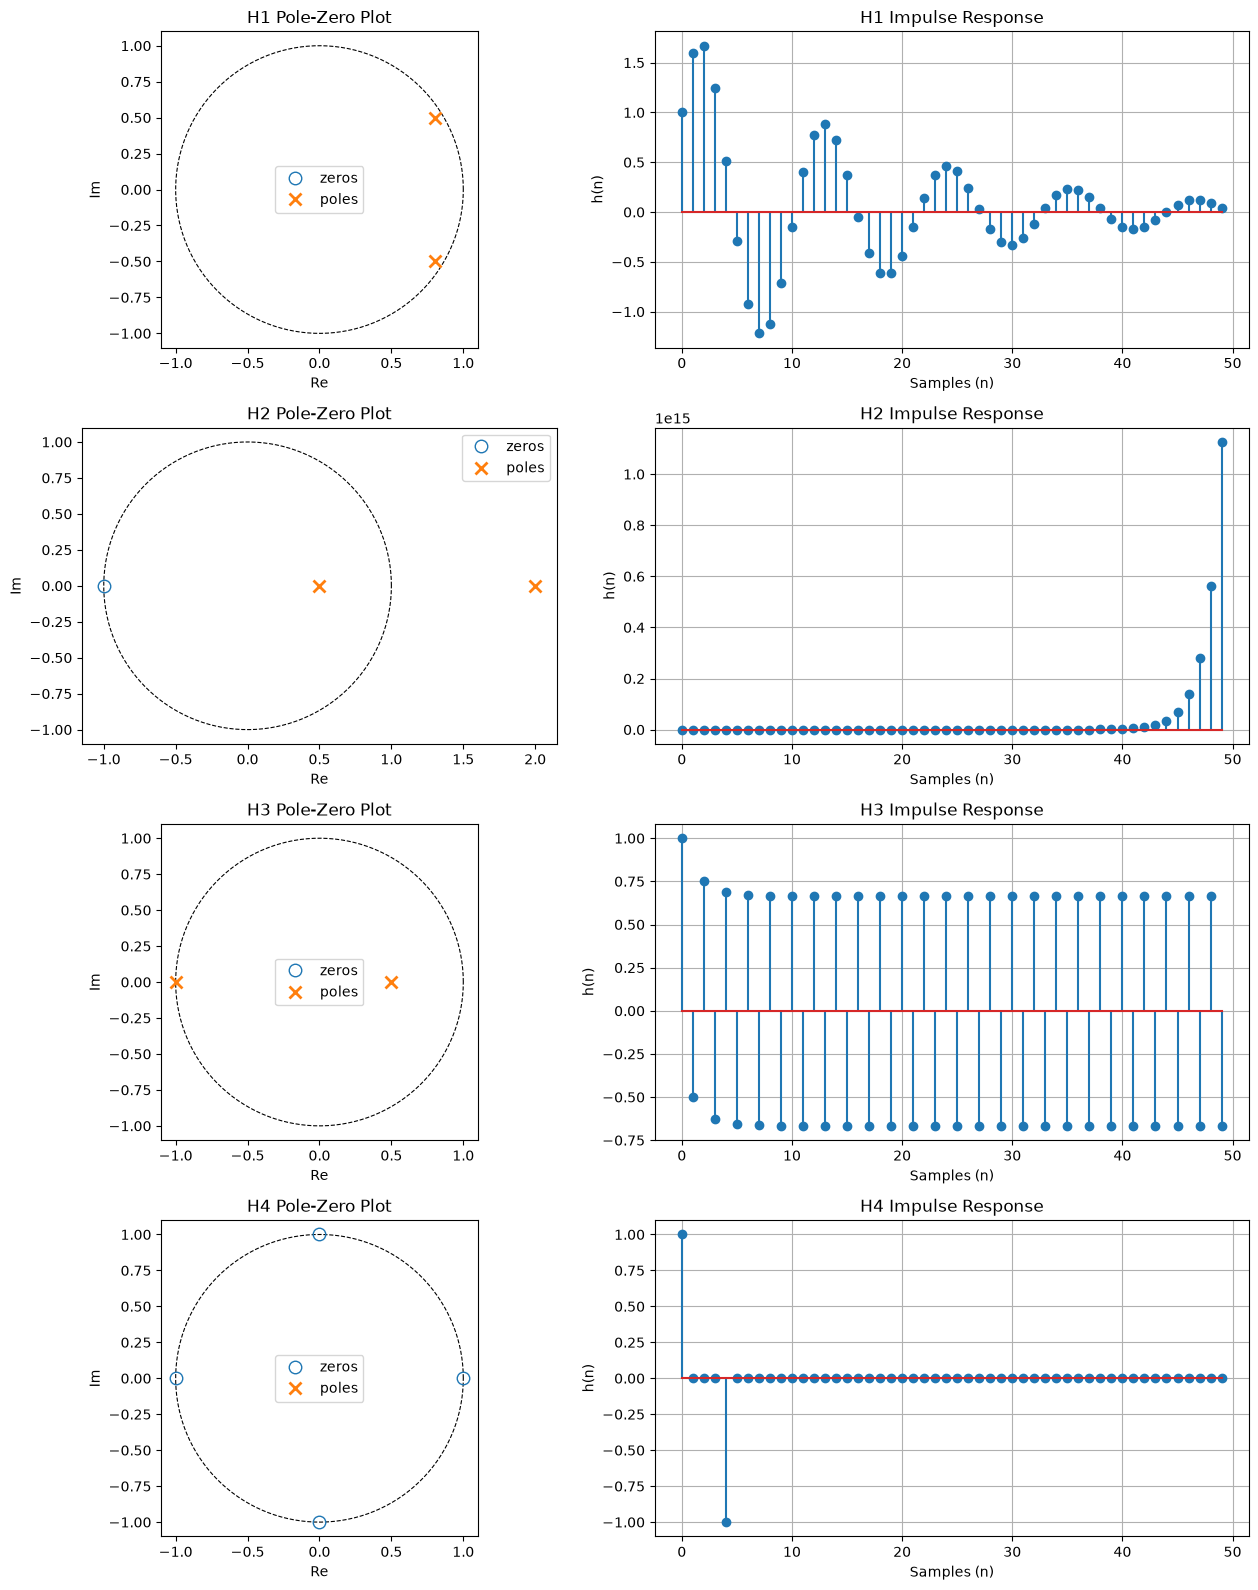

In [7]:

# TASK 4.4: Stability of Given Systems

# Define the four systems
systems = {
    "H1": ([1], [1, -1.6, 0.89]),
    "H2": ([1, 1], [1, -2.5, 1]),
    "H3": ([1], [1, 0.5, -0.5]),
    "H4": ([1, 0, 0, 0, -1], [1])
}

# Generate 50 impulse response samples
N = 50
impulse = np.zeros(N)
impulse[0] = 1

# Create plots
fig, axes = plt.subplots(4, 2, figsize=(13, 16))

for i, (name, (b, a)) in enumerate(systems.items()):

    # Calculate poles and zeros
    z, p, k = signal.tf2zpk(b, a)

    # Check stability
    stable = np.all(np.abs(p) < 1)

    # Calculate impulse response
    h = signal.lfilter(b, a, impulse)

    # Display results
    print(name)
    print("Zeros:", z)
    print("Poles:", p)
    print("Pole magnitudes:", np.abs(p))
    print("Stability:", "Stable" if stable else "Unstable")
    print("--------------------------------")

    # Pole-zero diagram
    zplane(b, a, axes[i, 0])
    axes[i, 0].set_title(f"{name} Pole-Zero Plot")

    # Impulse response
    axes[i, 1].stem(np.arange(N), h)
    axes[i, 1].set_title(f"{name} Impulse Response")
    axes[i, 1].set_xlabel("Samples (n)")
    axes[i, 1].set_ylabel("h(n)")
    axes[i, 1].grid()

plt.tight_layout()
plt.show()


### Task 4.4 Observations

H1 is stable because all its poles are inside the unit circle.

H2 is unstable because one pole is outside the unit circle, causing the impulse response to grow.

H3 is unstable because one pole lies on the unit circle. Its impulse response does not decay to zero.

H4 is stable because it has a finite impulse response.

Therefore, H1 and H4 are stable, while H2 and H3 are unstable.

## Task 4.5: Design of a Digital Resonator

### Objective
To design a digital resonator with a centre frequency of 1000 Hz, sampling frequency of 8000 Hz, and pole radius of 0.97. The system will be tested using white noise.

In [8]:
# TASK 4.5: Design a Digital Resonator

# Given values
fs = 8000
f0 = 1000
r = 0.97

# Calculate the resonant frequency angle
theta = 2 * np.pi * f0 / fs

# Design the denominator using the pole radius
a = [1, -2 * r * np.cos(theta), r**2]

# Place zeros at z = +1 and z = -1
b = [1, 0, -1]

# Calculate poles, zeros and gain
z, p, k = signal.tf2zpk(b, a)

print("Numerator coefficients:", b)
print("Denominator coefficients:", a)
print("Zeros:", z)
print("Poles:", p)
print("Pole magnitudes:", np.abs(p))

Numerator coefficients: [1, 0, -1]
Denominator coefficients: [1, np.float64(-1.3717871555019023), 0.9409]
Zeros: [-1.  1.]
Poles: [0.68589358+0.68589358j 0.68589358-0.68589358j]
Pole magnitudes: [0.97 0.97]


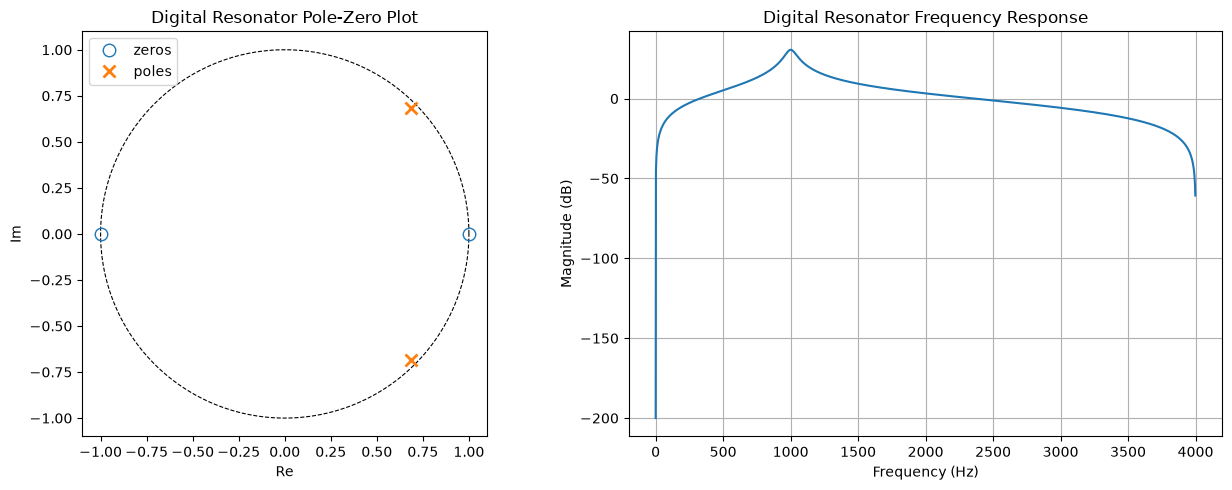

In [9]:
# Plot pole-zero diagram and frequency response

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Pole-zero plot
zplane(b, a, axes[0])
axes[0].set_title("Digital Resonator Pole-Zero Plot")

# Frequency response
w, H = signal.freqz(b, a, worN=2048, fs=fs)

axes[1].plot(w, 20 * np.log10(np.maximum(np.abs(H), 1e-10)))
axes[1].set_title("Digital Resonator Frequency Response")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Magnitude (dB)")
axes[1].grid()

plt.tight_layout()
plt.show()

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio, display

In [4]:
# Task 4.5 setup

fs = 8000
f0 = 1000
r = 0.97

theta = 2 * np.pi * f0 / fs

a = [1, -2 * r * np.cos(theta), r**2]
b = [1, 0, -1]

z, p, k = signal.tf2zpk(b, a)

print("Sampling frequency:", fs, "Hz")
print("Resonant frequency:", f0, "Hz")
print("Pole radius:", r)

Sampling frequency: 8000 Hz
Resonant frequency: 1000 Hz
Pole radius: 0.97


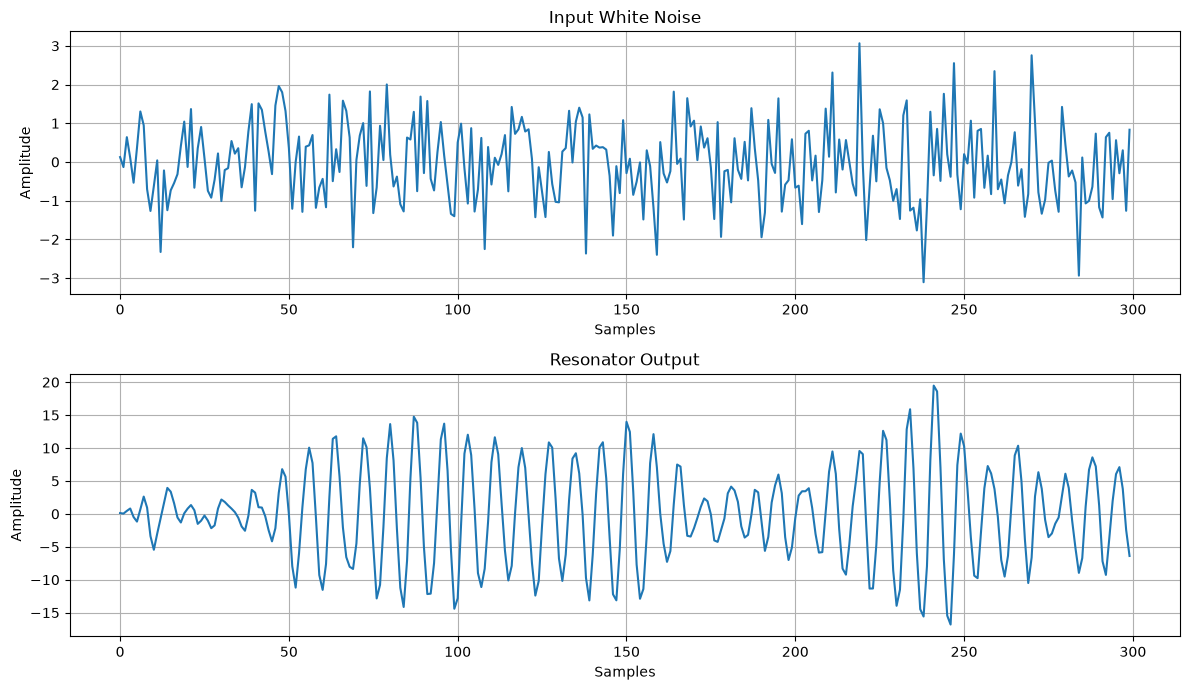

In [5]:
# Generate white noise
rng = np.random.default_rng(0)
x = rng.normal(0, 1, fs * 2)

# Apply the digital resonator
y = signal.lfilter(b, a, x)

# Normalize output for audio playback
y_audio = y / np.max(np.abs(y))

# Display input and output signals
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(x[:300])
axes[0].set_title("Input White Noise")
axes[0].set_xlabel("Samples")
axes[0].set_ylabel("Amplitude")
axes[0].grid()

axes[1].plot(y[:300])
axes[1].set_title("Resonator Output")
axes[1].set_xlabel("Samples")
axes[1].set_ylabel("Amplitude")
axes[1].grid()

plt.tight_layout()
plt.show()

In [6]:
# Listen to the resonator output

display(Audio(y_audio, rate=fs))

### Task 4.5 Observations

The digital resonator was designed with a sampling frequency of 8000 Hz, resonant frequency of 1000 Hz, and pole radius of 0.97.

The pole-zero plot showed two poles inside the unit circle and two zeros at z = +1 and z = -1.

The frequency response showed a strong peak around 1000 Hz.

After applying the resonator to white noise, frequencies around 1000 Hz were emphasized. The output sounded more tone-like than the original white noise.

The simulation demonstrated how pole locations control the resonant frequency and bandwidth of a digital resonator.

# Analysis Questions 

### Question 1
**How does increasing the pole radius affect the bandwidth and sharpness of the frequency response?**

Increasing the pole radius towards 1 makes the bandwidth narrower and the frequency response peak sharper. A smaller pole radius produces a wider bandwidth and a less sharp peak.

### Question 2
**What happens when a pole lies exactly on the unit circle?**

The system produces an oscillation that does not decay. For a causal system, it is not BIBO stable.

### Question 3
**Why are zeros placed at z = +1 and z = -1 in Task 4.5?**

The zero at z = +1 blocks DC (0 Hz), while the zero at z = -1 blocks the Nyquist frequency (4000 Hz). This helps the resonator emphasize frequencies around 1000 Hz.

### Question 4
**Use the stability triangle to check the stability of systems H1, H2 and H3 in Task 4.4.**

- **H1:** Stable. It satisfies all the stability triangle conditions.
- **H2:** Unstable. It fails the stability conditions.
- **H3:** Unstable in the BIBO sense. It has a pole at -1, exactly on the unit circle, so it fails the strict stability condition.

# Conclusion

The laboratory demonstrated how to calculate poles and zeros, perform inverse z-transforms, analyze frequency responses, and determine the stability of discrete-time systems. It also showed how pole locations affect system stability and resonator performance.

## AI Use Statement

I used ChatGPT as an AI assistance tool to help me understand the laboratory instructions, explain z-transform concepts, write and correct Python code, troubleshoot errors, and interpret simulation results. I reviewed and ran the code and completed the laboratory activities myself.